# Comparación de Finetuning: Optuna vs Grid Search

Este notebook compara los resultados de **finetuning** obtenidos con dos estrategias de búsqueda de hiperparámetros sobre `yolo26m`:

| Método | Archivo | Estrategia |
|---|---|---|
| **Grid Search** | `artifacts/data_comparativa_modelos_11_1.csv` | Rejilla exhaustiva de 72 combinaciones |
| **Optuna** | `artifacts/results_opt_11.csv` | Búsqueda secuencial TPE de 50 trials |

El análisis amplía lo revisado en `21_resultados_finetuning_1.ipynb` y cubre:

1. Cobertura del espacio de búsqueda.
2. Estadísticas descriptivas y mejores configuraciones.
3. Distribución, dispersión y estabilidad de los resultados.
4. Convergencia por experimento y por tiempo.
5. Eficiencia computacional.
6. Efecto de los hiperparámetros.


## 0. Configuración y carga de datos

Se cargan ambos archivos y se estandariza el esquema de Optuna para que use los mismos nombres de columna que Grid Search.

In [1]:
import os
from pathlib import Path

BASE_DIR = Path(r"B:\12RossyDocumentos\12ProyectoGallinas\11Avance\13_proyecto_gallinas")
if BASE_DIR.exists():
    os.chdir(BASE_DIR)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

plt.style.use("seaborn-v0_8-darkgrid")
sns.set_palette("Set2")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 220)

RANDOM_STATE = 42
ORDEN = ["Grid Search", "Optuna"]
COLORES = {"Grid Search": "#4C72B0", "Optuna": "#DD8452"}

%matplotlib inline

In [2]:
RUTA_GS = "artifacts/data_comparativa_modelos_11_1.csv"
RUTA_OPT = "artifacts/results_opt_11.csv"

gs = pd.read_csv(RUTA_GS)
opt = pd.read_csv(RUTA_OPT)

# --- Estandarización de Optuna al esquema de Grid Search ---
opt = opt.rename(columns={
    "value": "map50_95",
    "params_MODEL_EPOCHS": "epocas_inicial",
    "params_MODEL_BATCH": "batch",
    "params_MODEL_LR": "learning_rate",
})

opt["numero"] = opt["number"] + 1  # Grid Search numera desde 1
opt["tiempo_horas"] = pd.to_timedelta(opt["duration"]).dt.total_seconds() / 3600
opt["optimizer"] = "SGD"           # fijo en el objective de Optuna
opt["metodo"] = "Optuna"

gs = gs.copy()
gs["metodo"] = "Grid Search"

# Métricas que solo exporta Grid Search
for col in ["map50", "precision", "recall"]:
    if col not in opt.columns:
        opt[col] = np.nan

columnas = [
    "metodo", "numero", "epocas_inicial", "batch", "learning_rate", "optimizer",
    "map50", "map50_95", "precision", "recall", "tiempo_horas",
]
comparacion = pd.concat([gs[columnas], opt[columnas]], ignore_index=True)
comparacion["tiempo_minutos"] = comparacion["tiempo_horas"] * 60

# Tiempo acumulado por experimento (para la convergencia en horas)
comparacion = comparacion.sort_values(["metodo", "numero"]).reset_index(drop=True)
comparacion["tiempo_acumulado_h"] = (
    comparacion.groupby("metodo")["tiempo_horas"].cumsum()
)

print(f"Grid Search : {len(gs):>3} experimentos")
print(f"Optuna      : {len(opt):>3} experimentos")
print(f"Combinado   : {len(comparacion):>3} experimentos")

Grid Search :  72 experimentos
Optuna      :  50 experimentos
Combinado   : 122 experimentos


In [3]:
display(gs.head(3))
display(
    opt[["numero", "epocas_inicial", "batch", "learning_rate",
         "optimizer", "map50_95", "tiempo_horas"]].head(3)
)
display(
    comparacion.groupby("metodo")
    .agg(
        experimentos=("numero", "size"),
        mejor_map50_95=("map50_95", "max"),
        media_map50_95=("map50_95", "mean"),
        tiempo_total_h=("tiempo_horas", "sum"),
    )
    .reindex(ORDEN)
    .round(4)
)

,numero,epocas_inicial,batch,learning_rate,optimizer,epocas_fin,total_imagenes,total_imagenes_train,total_imagenes_val,tiempo_minutos,tiempo_horas,map50,map50_95,precision,recall,metodo
0,1,50,6,0.10,SGD,50,63,50,13,1.408758,0.023479,0.38426,0.12291,0.35397,0.58957,Grid Search
1,2,50,6,0.10,AdamW,50,63,50,13,2.458800,0.040980,0.01589,0.00271,0.06201,0.13904,Grid Search
2,3,50,6,0.01,SGD,50,63,50,13,1.423165,0.023719,0.54482,0.18040,0.61843,0.58938,Grid Search


,numero,epocas_inicial,batch,learning_rate,optimizer,map50_95,tiempo_horas
0,1,186,11,0.085329,SGD,0.18870,0.071343
1,2,178,8,0.035063,SGD,0.20200,0.075099
2,3,176,12,0.065615,SGD,0.19315,0.070275


,experimentos,mejor_map50_95,media_map50_95,tiempo_total_h
metodo,,,,
Grid Search,72,0.2250,0.1357,3.2074
Optuna,50,0.2297,0.2045,3.8712


## 1. Diseño experimental y cobertura del espacio de búsqueda

Antes de comparar métricas conviene verificar **qué espacio exploró cada método**. Grid Search recorre una rejilla fija; Optuna muestrea secuencialmente y concentra los trials en las regiones que mejoran la métrica objetivo.

In [4]:
def rango_numerico(serie, entero=False):
    vals = np.sort(serie.dropna().unique())
    fmt = "{:.0f}" if entero else "{:.4f}"
    if len(vals) > 12:
        return f"{fmt.format(vals.min())} – {fmt.format(vals.max())} ({len(vals)} valores)"
    return ", ".join(fmt.format(v) for v in vals)


espacio = pd.DataFrame(
    {
        "Grid Search": [
            len(gs),
            rango_numerico(gs["epocas_inicial"], entero=True),
            rango_numerico(gs["batch"], entero=True),
            rango_numerico(gs["learning_rate"]),
            ", ".join(sorted(gs["optimizer"].unique())),
            "Rejilla exhaustiva (3 × 4 × 3 × 2 = 72)",
        ],
        "Optuna": [
            len(opt),
            rango_numerico(opt["epocas_inicial"], entero=True),
            rango_numerico(opt["batch"], entero=True),
            rango_numerico(opt["learning_rate"]),
            ", ".join(sorted(opt["optimizer"].unique())),
            "TPE secuencial (50 trials)",
        ],
    },
    index=[
        "Experimentos", "Épocas", "Batch", "Learning rate",
        "Optimizador", "Estrategia",
    ],
)
display(espacio)

,Grid Search,Optuna
Experimentos,72,50
Épocas,"50, 100, 150",104 – 300 (42 valores)
Batch,"6, 8, 10, 12","8, 9, 10, 11, 12"
Learning rate,"0.0010, 0.0100, 0.1000",0.0013 – 0.0991 (50 valores)
Optimizador,"AdamW, SGD",SGD
Estrategia,Rejilla exhaustiva (3 × 4 × 3 × 2 = 72),TPE secuencial (50 trials)


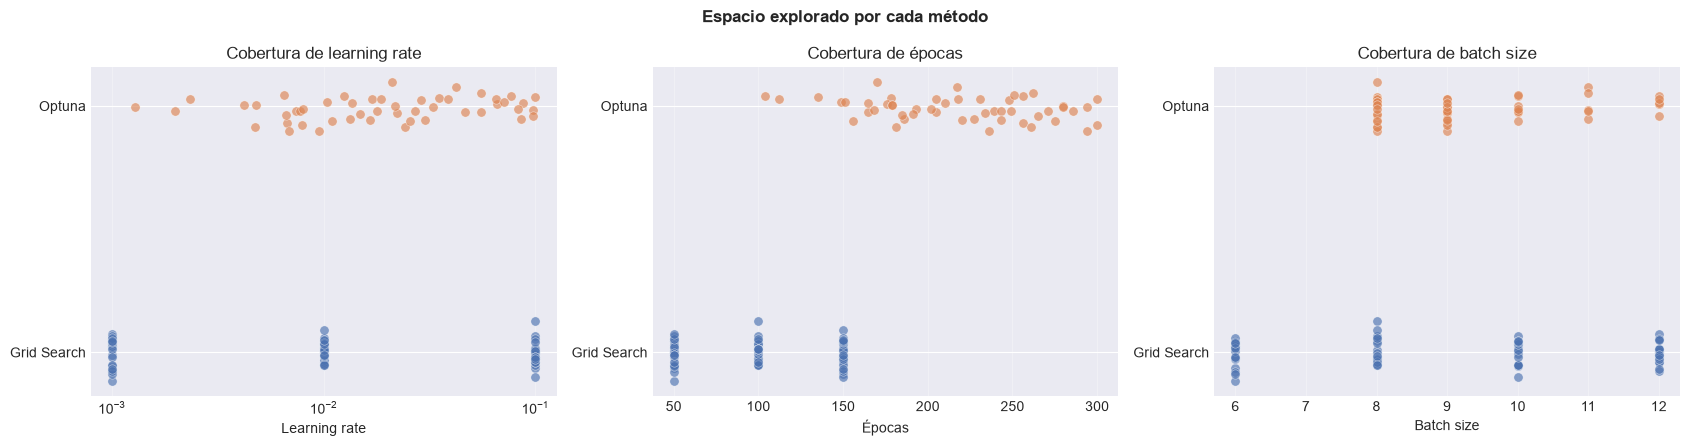

In [5]:
rng = np.random.default_rng(RANDOM_STATE)
com_plot = comparacion.copy()
com_plot["y"] = com_plot["metodo"].map({m: i for i, m in enumerate(ORDEN)})
com_plot["y"] = com_plot["y"] + rng.normal(0, 0.06, len(com_plot))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
configs = [
    ("learning_rate", "Learning rate", True),
    ("epocas_inicial", "Épocas", False),
    ("batch", "Batch size", False),
]
for ax, (col, titulo, logx) in zip(axes, configs):
    for metodo in ORDEN:
        sub = com_plot[com_plot["metodo"] == metodo]
        ax.scatter(
            sub[col], sub["y"], s=45, alpha=0.65, label=metodo,
            color=COLORES[metodo], edgecolor="white", linewidth=0.4,
        )
    if logx:
        ax.set_xscale("log")
    ax.set_yticks(range(len(ORDEN)))
    ax.set_yticklabels(ORDEN)
    ax.set_xlabel(titulo)
    ax.set_title(f"Cobertura de {titulo.lower()}")
    ax.grid(True, axis="x", alpha=0.3)

fig.suptitle("Espacio explorado por cada método", fontweight="bold")
plt.tight_layout()
plt.show()

**Lectura.** Grid Search cubre una rejilla cerrada de 3 valores de épocas, 4 de batch y 3 de learning rate, combinada con 2 optimizadores. Optuna explora un espacio más amplio en épocas (`100–300`) y learning rate (`0.001–0.1`, continuo), pero con un presupuesto menor de trials. La diferencia clave es que Optuna **no desperdicia trials en combinaciones ya descartadas**, mientras que Grid Search debe evaluar todas las celdas, incluidas las malas.

## 2. Estadísticas descriptivas y mejores configuraciones

Se compara la distribución de `mAP50-95`, la métrica objetivo de ambos procesos, junto con el costo temporal de cada método.

In [6]:
filas = []
for metodo, df in comparacion.groupby("metodo"):
    s = df["map50_95"]
    filas.append({
        "Método": metodo,
        "Experimentos": len(df),
        "Media": s.mean(),
        "Desv. estándar": s.std(),
        "CV": s.std() / s.mean(),
        "Mínimo": s.min(),
        "Q25": s.quantile(0.25),
        "Mediana": s.median(),
        "Q75": s.quantile(0.75),
        "Máximo": s.max(),
        "Rango": s.max() - s.min(),
        "Tiempo total (h)": df["tiempo_horas"].sum(),
        "Tiempo medio (min)": df["tiempo_minutos"].mean(),
    })

resumen = pd.DataFrame(filas).set_index("Método").reindex(ORDEN)
display(
    resumen.style
    .format({
        "Experimentos": "{:.0f}",
        "Media": "{:.4f}",
        "Desv. estándar": "{:.4f}",
        "CV": "{:.2%}",
        "Mínimo": "{:.4f}",
        "Q25": "{:.4f}",
        "Mediana": "{:.4f}",
        "Q75": "{:.4f}",
        "Máximo": "{:.4f}",
        "Rango": "{:.4f}",
        "Tiempo total (h)": "{:.2f}",
        "Tiempo medio (min)": "{:.2f}",
    })
    .background_gradient(subset=["Media", "Mediana", "Máximo"], cmap="YlGn")
)

,Experimentos,Media,Desv. estándar,CV,Mínimo,Q25,Mediana,Q75,Máximo,Rango,Tiempo total (h),Tiempo medio (min)
Método,,,,,,,,,,,,
Grid Search,72,0.1357,0.0772,56.85%,0.0017,0.0862,0.1710,0.2015,0.2250,0.2233,3.21,2.67
Optuna,50,0.2045,0.0305,14.91%,0.0362,0.1996,0.2116,0.2207,0.2297,0.1935,3.87,4.65


In [7]:
def fila_mejor(df):
    orden = df.sort_values("numero").copy()
    orden["tiempo_acumulado_h"] = orden["tiempo_horas"].cumsum()
    return orden.loc[orden["map50_95"].idxmax()]


filas_mejores = []
for metodo, df in comparacion.groupby("metodo"):
    r = fila_mejor(df)
    filas_mejores.append({
        "Método": metodo,
        "Trial": int(r["numero"]),
        "Épocas": int(r["epocas_inicial"]),
        "Batch": int(r["batch"]),
        "Learning rate": r["learning_rate"],
        "Optimizador": r["optimizer"],
        "mAP50-95": r["map50_95"],
        "Tiempo del trial (min)": r["tiempo_horas"] * 60,
        "Tiempo acumulado (h)": r["tiempo_acumulado_h"],
    })

mejores = pd.DataFrame(filas_mejores).set_index("Método").reindex(ORDEN)
display(
    mejores.style
    .format({
        "Trial": "{:.0f}",
        "Épocas": "{:.0f}",
        "Batch": "{:.0f}",
        "Learning rate": "{:.6g}",
        "mAP50-95": "{:.4f}",
        "Tiempo del trial (min)": "{:.2f}",
        "Tiempo acumulado (h)": "{:.2f}",
    })
    .background_gradient(subset=["mAP50-95"], cmap="YlGn")
)

mejor_gs = gs.loc[gs["map50_95"].idxmax()]
print("Métricas completas de la mejor corrida de Grid Search:")
display(mejor_gs[["numero", "map50", "map50_95", "precision", "recall"]].to_frame().T)

,Trial,Épocas,Batch,Learning rate,Optimizador,mAP50-95,Tiempo del trial (min),Tiempo acumulado (h)
Método,,,,,,,,
Grid Search,57,150,8,0.01,SGD,0.2250,3.18,2.33
Optuna,41,185,8,0.00663663,SGD,0.2297,4.75,3.21


Métricas completas de la mejor corrida de Grid Search:


,numero,map50,map50_95,precision,recall
56,57,0.62927,0.22499,0.66027,0.65241


**Lectura.** Optuna obtiene un máximo superior (`0.2297` frente a `0.2250`) y, sobre todo, una distribución mucho más consistente: su media (`0.2045`) y mediana (`0.2116`) están muy por encima de las de Grid Search (`0.1357` y `0.1710`). La desviación estándar de Optuna (`0.0305`) es menos de la mitad que la de Grid Search (`0.0772`).

Grid Search promedia bajo porque evalúa de forma obligatoria combinaciones poco favorables, como `LR = 0.1` o el optimizador `AdamW`. Optuna concentra el presupuesto en la zona útil. El CSV de Optuna solo exporta la métrica objetivo (`value`), por lo que `precision` y `recall` no están disponibles para comparar entre métodos.

## 3. Distribución, dispersión y estabilidad

Los boxplots y la ECDF permiten ver no solo el mejor resultado, sino también **cuán probable es obtener una configuración buena** con cada estrategia.

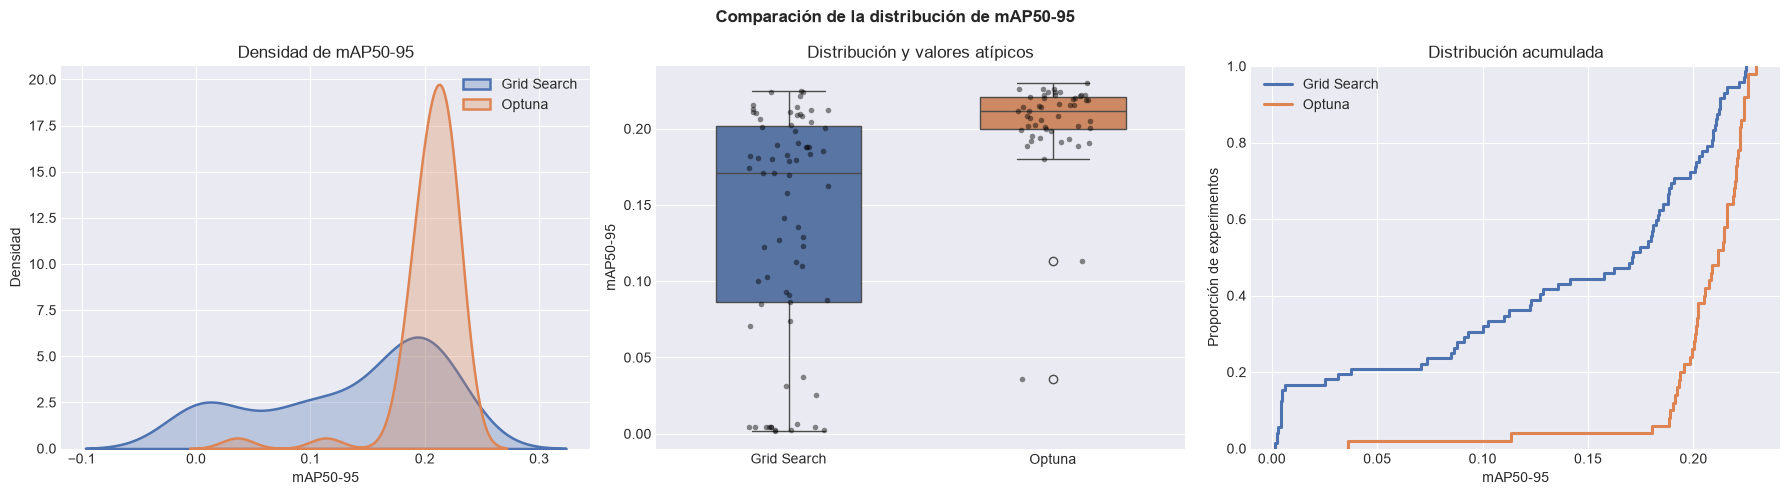

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# --- Densidad ---
for metodo in ORDEN:
    sns.kdeplot(
        data=comparacion[comparacion["metodo"] == metodo],
        x="map50_95", fill=True, alpha=0.30, linewidth=1.8,
        label=metodo, color=COLORES[metodo], ax=axes[0],
    )
axes[0].set_title("Densidad de mAP50-95")
axes[0].set_xlabel("mAP50-95")
axes[0].set_ylabel("Densidad")
axes[0].legend()

# --- Boxplot + puntos ---
sns.boxplot(
    data=comparacion, x="metodo", y="map50_95", order=ORDEN,
    hue="metodo", palette=COLORES, legend=False,
    width=0.55, ax=axes[1],
)
sns.stripplot(
    data=comparacion, x="metodo", y="map50_95", order=ORDEN,
    color="black", alpha=0.45, size=4, jitter=0.15, ax=axes[1],
)
axes[1].set_title("Distribución y valores atípicos")
axes[1].set_xlabel("")
axes[1].set_ylabel("mAP50-95")

# --- ECDF ---
for metodo in ORDEN:
    sns.ecdfplot(
        data=comparacion[comparacion["metodo"] == metodo],
        x="map50_95", label=metodo, color=COLORES[metodo],
        linewidth=2.2, ax=axes[2],
    )
axes[2].set_title("Distribución acumulada")
axes[2].set_xlabel("mAP50-95")
axes[2].set_ylabel("Proporción de experimentos")
axes[2].legend()

fig.suptitle("Comparación de la distribución de mAP50-95", fontweight="bold")
plt.tight_layout()
plt.show()

## 4. Convergencia: experimentos vs tiempo


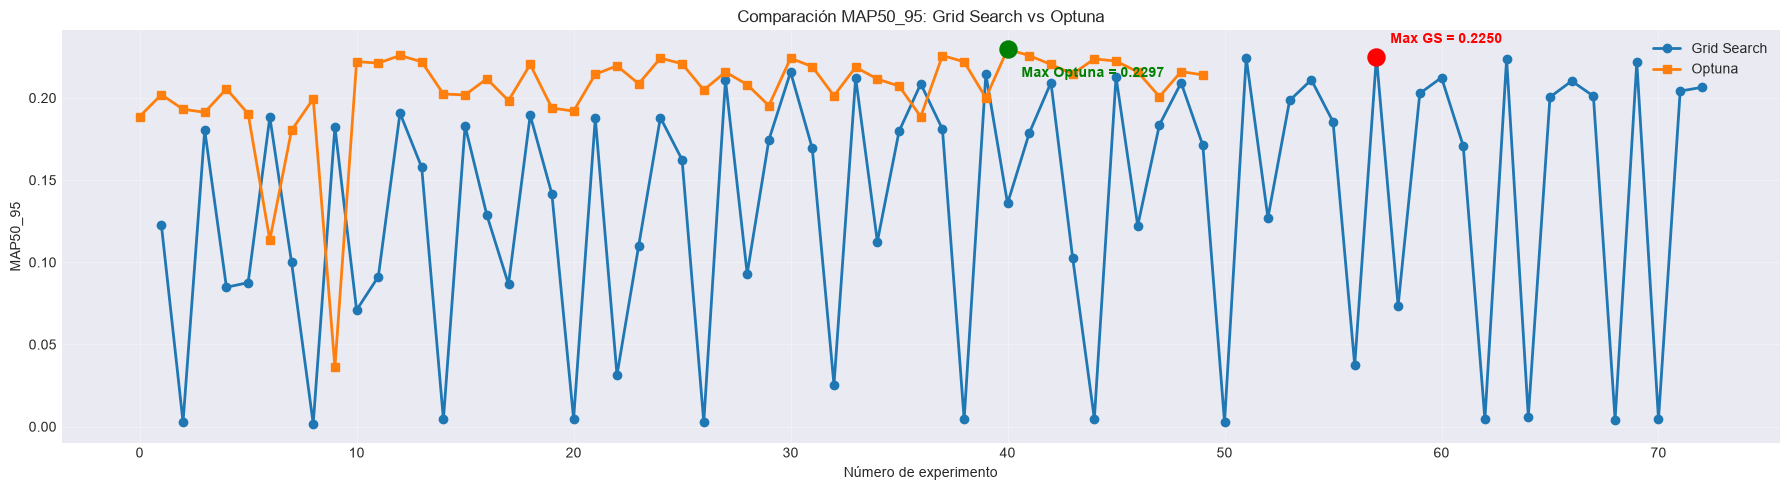

In [23]:
plt.figure(figsize=(18, 5))

# Gráfico de líneas
plt.plot(
    gs["numero"],
    gs["map50_95"],
    marker="o",
    linewidth=2,
    label="Grid Search",
    color="tab:blue"
)

plt.plot(
    opt["number"],
    opt["map50_95"],
    marker="s",
    linewidth=2,
    label="Optuna",
    color="tab:orange"
)

# Máximo Grid Search
idx_gs = gs["map50_95"].idxmax()
x_gs = gs.loc[idx_gs, "numero"]
y_gs = gs.loc[idx_gs, "map50_95"]

plt.scatter(x_gs, y_gs, color="red", s=150, zorder=5)
plt.annotate(
    f"Max GS = {y_gs:.4f}",
    (x_gs, y_gs),
    xytext=(10, 10),
    textcoords="offset points",
    color="red",
    fontweight="bold"
)

# Máximo Optuna
idx_opt = opt["map50_95"].idxmax()
x_opt = opt.loc[idx_opt, "number"]
y_opt = opt.loc[idx_opt, "map50_95"]

plt.scatter(x_opt, y_opt, color="green", s=150, zorder=5)
plt.annotate(
    f"Max Optuna = {y_opt:.4f}",
    (x_opt, y_opt),
    xytext=(10, -20),
    textcoords="offset points",
    color="green",
    fontweight="bold"
)

plt.title("Comparación MAP50_95: Grid Search vs Optuna")
plt.xlabel("Número de experimento")
plt.ylabel("MAP50_95")
plt.grid(True, alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()

## 5. Eficiencia computacional

El mejor resultado absoluto no es el único criterio: también importa cuánto cuesta cada trial y cuánto tiempo se invierte hasta alcanzar una calidad determinada.

In [12]:
filas = []
for metodo in ORDEN:
    d = comparacion[comparacion["metodo"] == metodo].sort_values("numero")
    mejor = d["map50_95"].max()
    r_mejor = d.loc[d["map50_95"].idxmax()]
    hit_95 = d[d["map50_95"] >= 0.95 * mejor].iloc[0]
    total = d["tiempo_horas"].sum()
    filas.append({
        "Método": metodo,
        "Experimentos": len(d),
        "Tiempo total (h)": total,
        "Tiempo medio por trial (min)": d["tiempo_horas"].mean() * 60,
        "Mejor mAP50-95": mejor,
        "mAP50-95 por hora": mejor / total,
        "Trial del mejor": int(r_mejor["numero"]),
        "Horas hasta el mejor": r_mejor["tiempo_acumulado_h"],
        "Trial al 95% del mejor": int(hit_95["numero"]),
        "Horas al 95% del mejor": hit_95["tiempo_acumulado_h"],
    })

eficiencia = pd.DataFrame(filas).set_index("Método").reindex(ORDEN)
display(
    eficiencia.style
    .format({
        "Experimentos": "{:.0f}",
        "Tiempo total (h)": "{:.2f}",
        "Tiempo medio por trial (min)": "{:.2f}",
        "Mejor mAP50-95": "{:.4f}",
        "mAP50-95 por hora": "{:.4f}",
        "Trial del mejor": "{:.0f}",
        "Horas hasta el mejor": "{:.2f}",
        "Trial al 95% del mejor": "{:.0f}",
        "Horas al 95% del mejor": "{:.2f}",
    })
    .background_gradient(subset=["Mejor mAP50-95", "mAP50-95 por hora"], cmap="YlGn")
)

,Experimentos,Tiempo total (h),Tiempo medio por trial (min),Mejor mAP50-95,mAP50-95 por hora,Trial del mejor,Horas hasta el mejor,Trial al 95% del mejor,Horas al 95% del mejor
Método,,,,,,,,,
Grid Search,72,3.21,2.67,0.2250,0.0701,57,2.33,30,0.91
Optuna,50,3.87,4.65,0.2297,0.0593,41,3.21,11,0.78


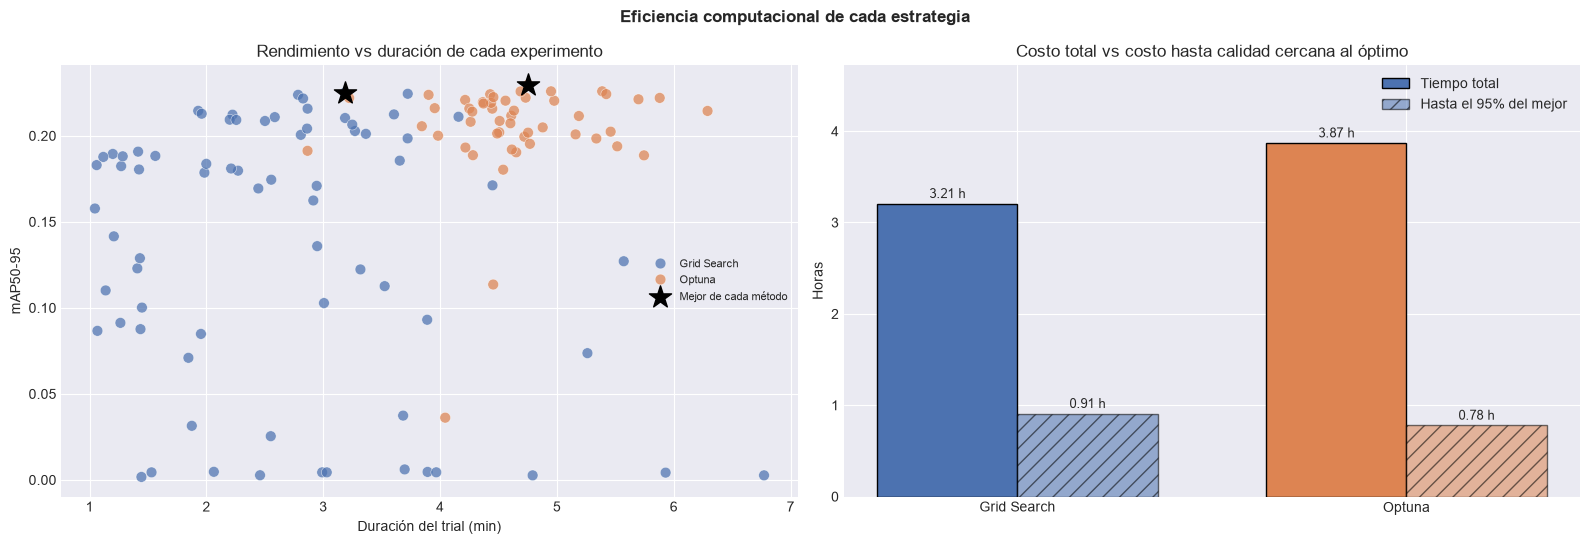

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

# --- Rendimiento vs duración de cada trial ---
sns.scatterplot(
    data=comparacion, x="tiempo_minutos", y="map50_95",
    hue="metodo", hue_order=ORDEN, palette=COLORES,
    s=60, alpha=0.72, edgecolor="white", linewidth=0.4, ax=axes[0],
)
axes[0].scatter(
    mejores["Tiempo del trial (min)"], mejores["mAP50-95"],
    marker="*", s=280, color="black", zorder=5,
    label="Mejor de cada método",
)
axes[0].set_xlabel("Duración del trial (min)")
axes[0].set_ylabel("mAP50-95")
axes[0].set_title("Rendimiento vs duración de cada experimento")
axes[0].legend(fontsize=8)

# --- Tiempo total vs tiempo hasta el 95% del mejor ---
x = np.arange(len(ORDEN))
total = [comparacion[comparacion["metodo"] == m]["tiempo_horas"].sum() for m in ORDEN]
hasta_95 = [eficiencia.loc[m, "Horas al 95% del mejor"] for m in ORDEN]

axes[1].bar(
    x - 0.18, total, 0.36,
    color=[COLORES[m] for m in ORDEN], edgecolor="black",
    label="Tiempo total",
)
axes[1].bar(
    x + 0.18, hasta_95, 0.36,
    color=[COLORES[m] for m in ORDEN], edgecolor="black",
    alpha=0.55, hatch="//", label="Hasta el 95% del mejor",
)
for i, (t, h) in enumerate(zip(total, hasta_95)):
    axes[1].text(i - 0.18, t + 0.06, f"{t:.2f} h", ha="center", fontsize=9)
    axes[1].text(i + 0.18, h + 0.06, f"{h:.2f} h", ha="center", fontsize=9)
axes[1].set_xticks(x)
axes[1].set_xticklabels(ORDEN)
axes[1].set_ylabel("Horas")
axes[1].set_title("Costo total vs costo hasta calidad cercana al óptimo")
axes[1].legend()
axes[1].set_ylim(0, max(total) * 1.22)

fig.suptitle("Eficiencia computacional de cada estrategia", fontweight="bold")
plt.tight_layout()
plt.show()

In [14]:
gs_total = comparacion.loc[comparacion["metodo"] == "Grid Search", "tiempo_horas"].sum()
opt_total = comparacion.loc[comparacion["metodo"] == "Optuna", "tiempo_horas"].sum()
gs_best = comparacion.loc[comparacion["metodo"] == "Grid Search", "map50_95"].max()
opt_best = comparacion.loc[comparacion["metodo"] == "Optuna", "map50_95"].max()

print(f"Optuna usa {len(opt)} trials frente a {len(gs)} de Grid Search "
      f"({(1 - len(opt) / len(gs)) * 100:.1f}% menos experimentos).")
print(f"Tiempo total: Optuna {opt_total:.2f} h vs Grid Search {gs_total:.2f} h "
      f"({(opt_total / gs_total - 1) * 100:+.1f}%).")
print(f"Mejora del máximo: {opt_best - gs_best:+.4f} mAP50-95 "
      f"({(opt_best / gs_best - 1) * 100:+.1f}% relativo).")

Optuna usa 50 trials frente a 72 de Grid Search (30.6% menos experimentos).
Tiempo total: Optuna 3.87 h vs Grid Search 3.21 h (+20.7%).
Mejora del máximo: +0.0047 mAP50-95 (+2.1% relativo).


**Lectura.** Optuna necesita **menos trials** (50 vs 72), pero cada trial es más largo porque entrena entre 100 y 300 épocas (media ≈ 218) frente a las 50–150 de Grid Search. Por eso su tiempo total es ~21% mayor. El costo por unidad de mejora es favorable a Optuna: obtiene un máximo superior y llega antes a una calidad alta, aunque su `mAP50-95 por hora` final sea ligeramente menor porque sigue explorando después del trial 11.

La comparación de "horas hasta el 95% del mejor" debe leerse con cautela: es un umbral **relativo al techo de cada método**, y el techo de Grid Search es más bajo. Por eso el análisis de umbrales absolutos de la sección 4 es más informativo.

## 6. Efecto de los hiperparámetros

Se analiza la relación entre cada hiperparámetro y `mAP50-95` mediante correlación de Spearman, diagramas de dispersión y mapas de calor de la interacción `learning rate × épocas`.

In [15]:
params = ["learning_rate", "batch", "epocas_inicial"]
etiquetas = {
    "learning_rate": "Learning rate",
    "batch": "Batch",
    "epocas_inicial": "Épocas",
}

filas = []
for metodo in ORDEN:
    d = comparacion[comparacion["metodo"] == metodo]
    for p in params:
        rho, pval = stats.spearmanr(d[p], d["map50_95"])
        filas.append({
            "Método": metodo,
            "Hiperparámetro": etiquetas[p],
            "rho": rho,
            "p-valor": pval,
        })

corr = pd.DataFrame(filas)
tabla_corr = (
    corr.pivot(index="Hiperparámetro", columns="Método", values=["rho", "p-valor"])
    .reindex(["Learning rate", "Batch", "Épocas"])
)
display(tabla_corr.round(4))

rho             p-valor        
Método         Grid Search  Optuna Grid Search  Optuna
Hiperparámetro                                        
Learning rate      -0.5263 -0.8983      0.0000  0.0000
Batch               0.0173 -0.4329      0.8851  0.0017
Épocas              0.2775  0.1748      0.0183  0.2248

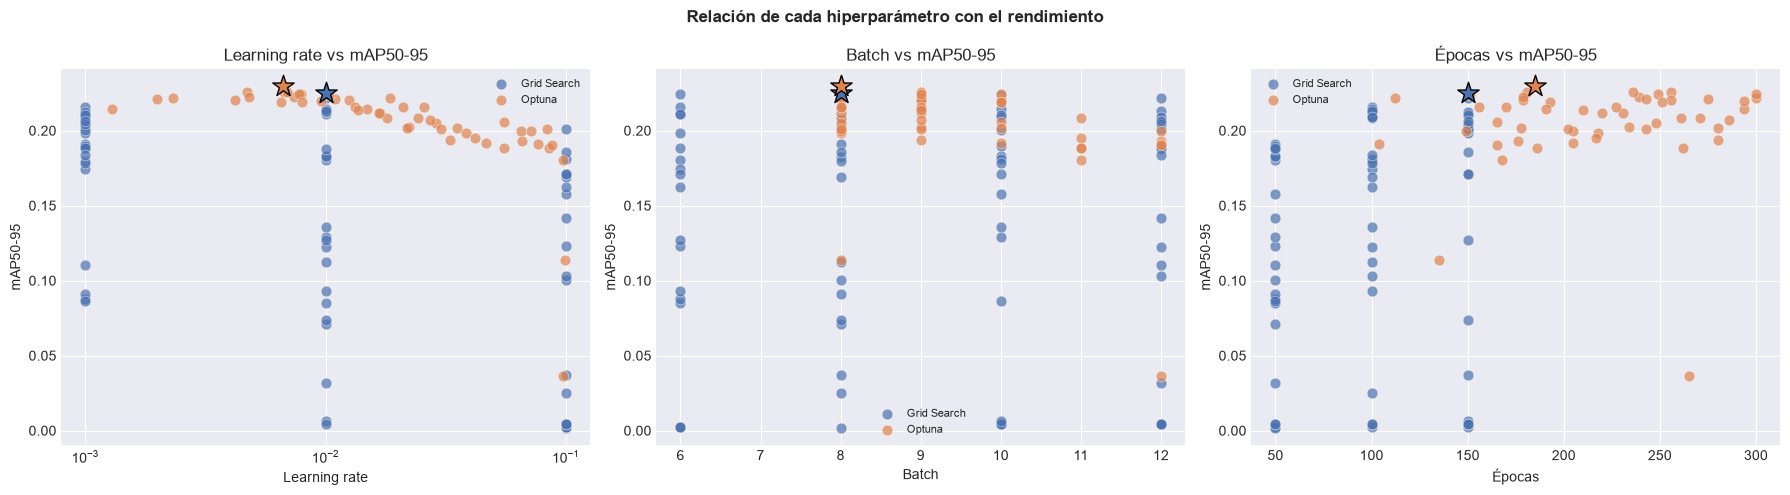

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
configs = [
    ("learning_rate", "Learning rate", True),
    ("batch", "Batch", False),
    ("epocas_inicial", "Épocas", False),
]
for ax, (col, titulo, logx) in zip(axes, configs):
    for metodo in ORDEN:
        d = comparacion[comparacion["metodo"] == metodo]
        sns.scatterplot(
            data=d, x=col, y="map50_95", label=metodo,
            color=COLORES[metodo], s=60, alpha=0.70,
            edgecolor="white", linewidth=0.4, ax=ax,
        )
        r = d.loc[d["map50_95"].idxmax()]
        ax.scatter(
            r[col], r["map50_95"], marker="*", s=260,
            color=COLORES[metodo], edgecolor="black", zorder=5,
        )
    if logx:
        ax.set_xscale("log")
    ax.set_xlabel(titulo)
    ax.set_ylabel("mAP50-95")
    ax.set_title(f"{titulo} vs mAP50-95")
    ax.legend(fontsize=8)

fig.suptitle("Relación de cada hiperparámetro con el rendimiento", fontweight="bold")
plt.tight_layout()
plt.show()

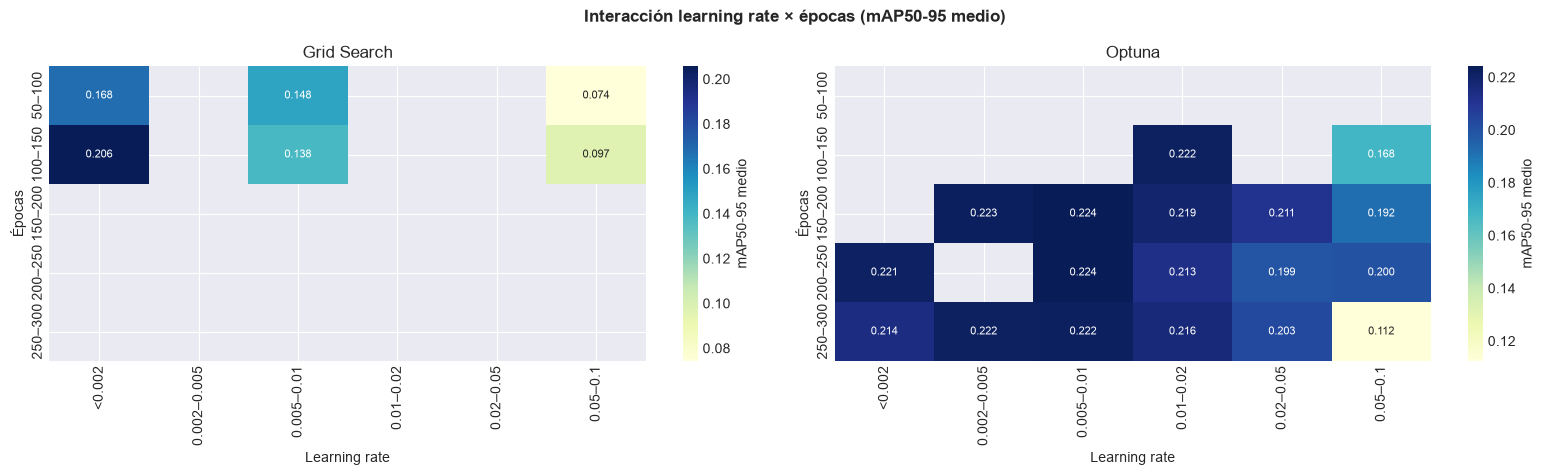

In [17]:
lr_edges = [0.0009, 0.002, 0.005, 0.01, 0.02, 0.05, 0.11]
lr_labels = ["<0.002", "0.002–0.005", "0.005–0.01",
             "0.01–0.02", "0.02–0.05", "0.05–0.1"]
ep_edges = [50, 100, 150, 200, 250, 300]
ep_labels = ["50–100", "100–150", "150–200", "200–250", "250–300"]

tmp = comparacion.copy()
tmp["lr_bin"] = pd.cut(
    tmp["learning_rate"], bins=lr_edges, labels=lr_labels, include_lowest=True
)
tmp["ep_bin"] = pd.cut(
    tmp["epocas_inicial"], bins=ep_edges, labels=ep_labels, include_lowest=True
)

fig, axes = plt.subplots(1, 2, figsize=(16, 4.8))
for ax, metodo in zip(axes, ORDEN):
    pivot = tmp[tmp["metodo"] == metodo].pivot_table(
        index="ep_bin", columns="lr_bin", values="map50_95",
        aggfunc="mean", observed=False,
    )
    pivot = pivot.reindex(index=ep_labels, columns=lr_labels)
    sns.heatmap(
        pivot, annot=True, fmt=".3f", cmap="YlGnBu",
        mask=pivot.isna(), ax=ax,
        cbar_kws={"label": "mAP50-95 medio"},
        annot_kws={"fontsize": 8},
    )
    ax.set_title(metodo)
    ax.set_xlabel("Learning rate")
    ax.set_ylabel("Épocas")

fig.suptitle("Interacción learning rate × épocas (mAP50-95 medio)", fontweight="bold")
plt.tight_layout()
plt.show()

In [18]:
print("Efecto marginal en Grid Search:")
for col, etiqueta in [
    ("learning_rate", "Learning rate"),
    ("optimizer", "Optimizador"),
    ("epocas_inicial", "Épocas"),
    ("batch", "Batch"),
]:
    tabla = (
        gs.groupby(col)["map50_95"]
        .agg(Experimentos="count", Media="mean", Máximo="max")
        .round(4)
    )
    tabla.index.name = etiqueta
    display(tabla)

Efecto marginal en Grid Search:


,Experimentos,Media,Máximo
Learning rate,,,
0.001,24,0.1807,0.2158
0.010,24,0.1446,0.2250
0.100,24,0.0819,0.2011


,Experimentos,Media,Máximo
Optimizador,,,
AdamW,36,0.0980,0.2158
SGD,36,0.1734,0.2250


,Experimentos,Media,Máximo
Épocas,,,
50,24,0.1132,0.1908
100,24,0.1469,0.2158
150,24,0.1471,0.2250


,Experimentos,Media,Máximo
Batch,,,
6,18,0.1367,0.2244
8,18,0.1379,0.2250
10,18,0.1383,0.2238
12,18,0.1300,0.2217


**Lectura.**

- **Learning rate:** es el hiperparámetro dominante. La correlación es negativa en ambos métodos (`-0.53` en Grid Search y `-0.90` en Optuna): los valores altos degradan el entrenamiento. En Grid Search, `LR = 0.001` da la mejor media (`0.1807`), pero su máximo aparece con `LR = 0.01` y 150 épocas (`0.2250`). Optuna concentra los mejores trials en `0.005–0.01`.
- **Optimizador:** en Grid Search, SGD supera claramente a AdamW (media `0.1734` vs `0.0980`). Optuna fija SGD, lo que elimina esa fuente de variabilidad.
- **Épocas:** la correlación es positiva pero débil (`0.28` en Grid Search, `0.17` en Optuna). Los mejores trials de Optuna usan entre 150 y 300 épocas, con mediana cercana a 230.
- **Batch:** en Grid Search su efecto es prácticamente nulo (`rho ≈ 0.02`) porque la rejilla lo balancea; en Optuna aparece una correlación negativa moderada (`-0.43`), con los mejores resultados en batch 8–9.

La mejor configuración de Grid Search (`150 épocas`, `batch 8`, `LR 0.01`, `SGD`) coincide en la zona que Optuna explota con más detalle: `LR ≈ 0.0066`, `batch 8`, `185 épocas`, `SGD`.

## Conclusiones

### Rendimiento

| Indicador | Grid Search | Optuna | Diferencia |
|---|---:|---:|---:|
| Mejor `mAP50-95` | 0.22499 | **0.22966** | +0.00467 (+2.1%) |
| Media | 0.13573 | **0.20451** | +0.06878 (+50.7%) |
| Mediana | 0.17103 | **0.21158** | +0.04055 |
| Desv. estándar | 0.07717 | **0.03050** | -60.5% |
| Coef. de variación | 56.9% | **14.9%** | -42.0 pp |

Optuna gana en **máximo, media, mediana y estabilidad**. La mejora del máximo es modesta (`+2.1%`), pero la mejora del rendimiento esperado es mucho mayor: un trial típico de Optuna rinde ~51% más que uno típico de Grid Search.

### Eficiencia y convergencia

- Grid Search: **72 trials**, **3.21 h**, **2.67 min/trial**.
- Optuna: **50 trials**, **3.87 h**, **4.65 min/trial**.
- Optuna usa **30.6% menos experimentos**, pero **20.7% más tiempo total** porque entrena con más épocas.
- Optuna alcanza `mAP50-95 ≥ 0.22` en el **trial 11 (0.78 h)**; Grid Search lo alcanza en el **trial 51 (1.93 h)**.
- El máximo de Optuna aparece en el trial 41, pero después del trial 11 la ganancia marginal es pequeña.

**Conclusión de eficiencia:** Optuna es más eficiente en **número de experimentos** y en **tiempo hasta una calidad alta**. Grid Search es más barato por trial, pero necesita muchos más trials para acercarse al mismo nivel.

### Hiperparámetros

- El **learning rate** es el factor más influyente. Valores altos (`≥ 0.05`) degradan el rendimiento; la zona útil está entre `0.002` y `0.02`, con el óptimo alrededor de `0.006–0.01`.
- **SGD** supera a **AdamW** en Grid Search (media `0.1734` vs `0.0980`). Optuna fija SGD y evita explorar una dimensión improductiva.
- El **batch** tiene un efecto pequeño; los mejores resultados aparecen con batch `8–9`.
- Las **épocas** muestran una relación positiva débil. Los mejores trials de Optuna usan `150–300` épocas, con mediana cercana a `230`.
